In [ ]:
!pip -q install osmnx geopandas networkx

In [ ]:
from google.colab import drive, files
drive.mount('/content/drive')

import os
import zipfile
import time
import heapq
import itertools
import hashlib
from pathlib import Path
from collections import deque

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt

from shapely.geometry import LineString, Point

SEED = 42
np.random.seed(SEED)

PROJECT_DIR = "/content/drive/MyDrive/nepal_flood_routing"
os.makedirs(PROJECT_DIR, exist_ok=True)

GRAPH_FILE = os.path.join(PROJECT_DIR, "nepal_roads.graphml")
print("OSMnx:", ox.__version__)
print("NetworkX:", nx.__version__)
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
OSMnx: 2.1.1
NetworkX: 3.7
Project folder: /content/drive/MyDrive/nepal_flood_routing


In [ ]:
uploaded = files.upload()  # Select nepal_flooding_road_blockages_28_08_2026.zip

zip_candidates = [
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
]
if not zip_candidates:
    raise FileNotFoundError("Upload the flood dataset ZIP file.")

ZIP_PATH = zip_candidates[0]
EXTRACT_DIR = os.path.join(PROJECT_DIR, "flood_dataset")
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

shp_files = list(Path(EXTRACT_DIR).rglob("*.shp"))
if not shp_files:
    raise FileNotFoundError("No .shp file was found inside the ZIP.")

shp_path = str(shp_files[0])
flood_gdf = gpd.read_file(shp_path)

if flood_gdf.crs is None:
    raise ValueError("The shapefile has no CRS; verify its source metadata.")

flood_gdf = flood_gdf.to_crs("EPSG:4326")
flood_gdf = flood_gdf[
    flood_gdf.geometry.notna() & ~flood_gdf.geometry.is_empty
].copy()

print("Shapefile:", shp_path)
print("Flood records:", len(flood_gdf))
print("Columns:", flood_gdf.columns.tolist())
print("CRS:", flood_gdf.crs)
display(flood_gdf.head())

if "damge_type" in flood_gdf.columns:
    display(flood_gdf["damge_type"].value_counts(dropna=False).to_frame("records"))

Saving nepal_flooding_road_blockages_28_08_2026.zip to nepal_flooding_road_blockages_28_08_2026 (2).zip
Shapefile: /content/drive/MyDrive/nepal_flood_routing/flood_dataset/nepal_flooding_road_blockages_28_08_2026.shp
Flood records: 22
Columns: ['id', 'image_name', 'damge_type', 'location', 'geometry']
CRS: EPSG:4326


,id,image_name,damge_type,location,geometry
0,1,1.png,severe flooding,near Gosaikunda-01,POINT (85.37852 28.27295)
1,2,2.png,severe flooding,Gosaikunda-01,POINT (85.36762 28.25758)
2,3,3.png,severe flooding,road NH42,POINT (85.36101 28.22246)
3,4,4.png,severe flooding,road NH42,POINT (85.35145 28.19706)
4,5,5.png,severe flooding,road NH42,POINT (85.34223 28.18163)


,records
damge_type,
severe flooding,19
flooding -moderate,3


OSM bbox (west, south, east, north): (np.float64(84.98966463867164), np.float64(27.79422547790736), np.float64(85.4314924055279), np.float64(28.302946663097945))


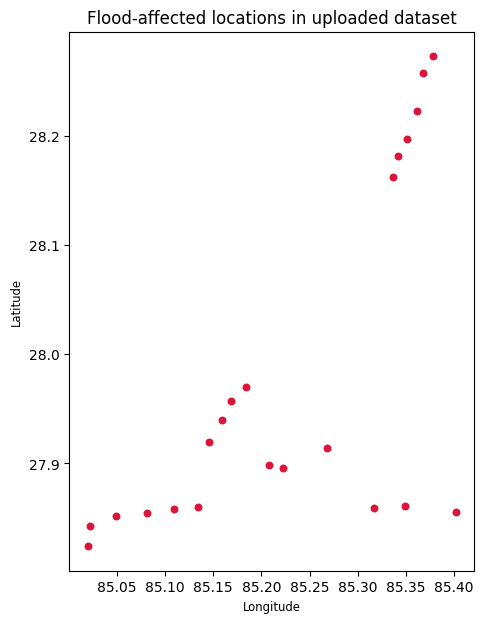

In [ ]:
# The bounding box is derived from the flood observations with a small buffer.
# Increase BUFFER_DEGREES only if you need a wider road network around the event area.
BUFFER_DEGREES = 0.03
west, south, east, north = flood_gdf.total_bounds
bbox = (
    west - BUFFER_DEGREES,
    south - BUFFER_DEGREES,
    east + BUFFER_DEGREES,
    north + BUFFER_DEGREES
)
print("OSM bbox (west, south, east, north):", bbox)

ax = flood_gdf.plot(figsize=(8, 7), color="crimson", markersize=22)
ax.set_title("Flood-affected locations in uploaded dataset")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

In [ ]:
if os.path.exists(GRAPH_FILE):
    print("Loading saved graph:", GRAPH_FILE)
    G_original = ox.load_graphml(GRAPH_FILE)
else:
    print("No saved graph found. Downloading the road network now...")
    G_original = ox.graph_from_bbox(
        bbox=bbox,
        network_type="drive",
        simplify=True,
        retain_all=False
    )
    ox.save_graphml(G_original, GRAPH_FILE)
    print("Saved graph to:", GRAPH_FILE)

print("Original graph nodes:", G_original.number_of_nodes())
print("Original graph directed edges:", G_original.number_of_edges())
print("Graph CRS:", G_original.graph.get("crs"))

Loading saved graph: /content/drive/MyDrive/nepal_flood_routing/nepal_roads.graphml
Original graph nodes: 2702
Original graph directed edges: 6176
Graph CRS: epsg:4326


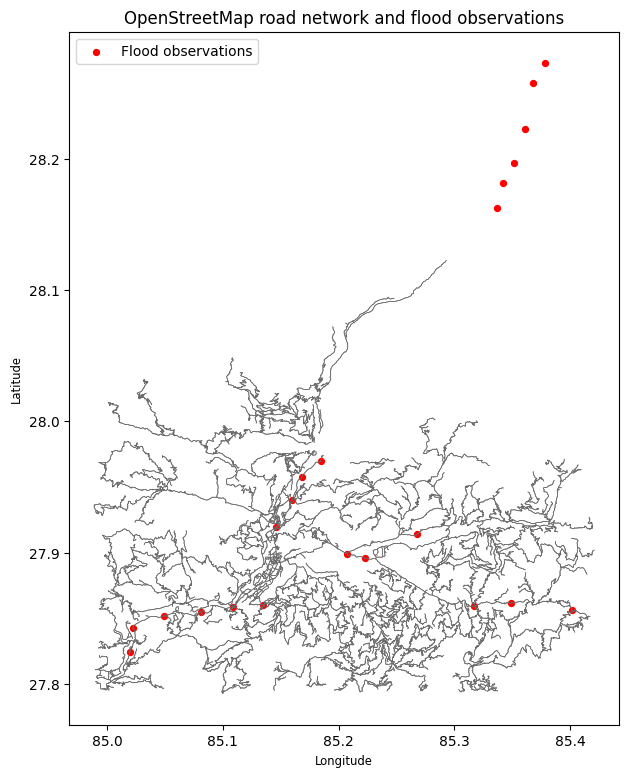

Start node: 3477704236 | snap distance (m): 649.7
Goal node: 14130888037 | snap distance (m): 2602.5


In [ ]:
# Display the road graph and flood points in geographic coordinates.
G_geo = G_original
nodes_geo, edges_geo = ox.graph_to_gdfs(G_geo, nodes=True, edges=True)

fig, ax = plt.subplots(figsize=(10, 9))
edges_geo.plot(ax=ax, linewidth=0.5, color="dimgray")
flood_gdf.plot(ax=ax, color="red", markersize=18, label="Flood observations")
ax.set_title("OpenStreetMap road network and flood observations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
plt.show()

# EDIT THESE PLACEHOLDERS after inspecting the map.
START_LATLON = (27.90, 85.10)
GOAL_LATLON  = (28.10, 85.30)

# Convert coordinates to nearest graph nodes. X is longitude, Y is latitude.
start_node = ox.distance.nearest_nodes(
    G_original, X=START_LATLON[1], Y=START_LATLON[0]
)
goal_node = ox.distance.nearest_nodes(
    G_original, X=GOAL_LATLON[1], Y=GOAL_LATLON[0]
)

def haversine_m(lat1, lon1, lat2, lon2):
    from math import radians, sin, cos, asin, sqrt
    R = 6371000.0
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = (
        sin(dlat / 2)**2
        + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2)**2
    )
    return 2 * R * asin(sqrt(a))

def snap_distance_m(coords, node, G):
    lat, lon = coords
    return haversine_m(
        lat, lon, G.nodes[node]["y"], G.nodes[node]["x"]
    )

start_snap_m = snap_distance_m(START_LATLON, start_node, G_original)
goal_snap_m = snap_distance_m(GOAL_LATLON, goal_node, G_original)

print("Start node:", start_node, "| snap distance (m):", round(start_snap_m, 1))
print("Goal node:", goal_node, "| snap distance (m):", round(goal_snap_m, 1))
if start_snap_m > 1000 or goal_snap_m > 1000:
    print("WARNING: At least one coordinate is over 1 km from its nearest road node. Recheck coordinates.")
if start_node == goal_node:
    print("WARNING: Start and goal snap to the same node. Choose different coordinates.")

In [ ]:
G_projected = ox.project_graph(G_original)
projected_crs = G_projected.graph["crs"]
flood_projected = flood_gdf.to_crs(projected_crs)

MATCH_DISTANCE_M = 150  # Set and report this threshold in your methodology.

match_rows = []
blocked_directed_edges = set()

for record_idx, row in flood_projected.iterrows():
    point = row.geometry
    u, v, k = ox.distance.nearest_edges(
        G_projected, X=point.x, Y=point.y
    )
    edge_data = G_projected.get_edge_data(u, v, k)

    if edge_data is None:
        continue

    geom = edge_data.get("geometry")
    if geom is None:
        geom = LineString([
            (G_projected.nodes[u]["x"], G_projected.nodes[u]["y"]),
            (G_projected.nodes[v]["x"], G_projected.nodes[v]["y"])
        ])

    distance_m = point.distance(geom)
    accepted = distance_m <= MATCH_DISTANCE_M

    severity = row.get("damge_type", "unknown")
    location = row.get("location", "unknown")

    match_rows.append({
        "record_index": record_idx,
        "location": location,
        "severity": severity,
        "u": u,
        "v": v,
        "key": k,
        "distance_m": float(distance_m),
        "within_threshold": bool(accepted)
    })

    if accepted:
        # Store directed edge IDs. We will handle a road as a physical closure
        # only when a matching reverse-direction segment is geometrically the same.
        blocked_directed_edges.add((u, v, k))

matches_df = pd.DataFrame(match_rows)
if matches_df.empty:
    raise RuntimeError("No road edges could be matched. Check graph coverage and coordinates.")

print("Flood records processed:", len(matches_df))
print("Records within threshold:", int(matches_df["within_threshold"].sum()))
print("Unique directed edges selected:", len(blocked_directed_edges))
display(matches_df.sort_values("distance_m").head(15))

Flood records processed: 22
Records within threshold: 16
Unique directed edges selected: 15


,record_index,location,severity,u,v,key,distance_m,within_threshold
18,18,road NH18,severe flooding,2345003561,2345003610,0,0.997553,True
15,15,road NH42,severe flooding,2440584530,3076918497,0,1.101787,True
10,10,road NH03,severe flooding,3491507654,3491793266,0,2.387487,True
14,14,road NH42,severe flooding,3076918497,2192565065,0,2.679878,True
21,21,road NH03,flooding -moderate,3488886583,12950048779,0,2.840942,True
16,16,road NH42,severe flooding,3477052091,3478311700,0,3.333336,True
20,20,road NH03,flooding -moderate,12946731955,3022035103,0,4.103320,True
17,17,road NH42,severe flooding,3477052342,1794867437,0,5.821063,True
11,11,road F181,severe flooding,3387810319,3387810299,0,6.863472,True
8,8,road NH42,severe flooding,3477473530,3486514020,0,7.691560,True


In [ ]:
# Start from a fresh projected graph each time this cell is run.
G_blocked = G_projected.copy()

# Remove the matched directed edge. If a reverse edge exists and its geometry
# closely overlaps the same physical segment, remove that reverse edge too.
# This avoids blindly closing reverse edges on separate/one-way roads.
accepted = matches_df[matches_df["within_threshold"]].copy()
edges_to_remove = set()

for _, row in accepted.iterrows():
    u, v, k = int(row["u"]), int(row["v"]), int(row["key"])
    if G_blocked.has_edge(u, v, k):
        edges_to_remove.add((u, v, k))

    if G_blocked.has_edge(v, u):
        forward_data = G_projected.get_edge_data(u, v, k)
        forward_geom = forward_data.get("geometry") if forward_data else None

        for reverse_k, reverse_data in G_projected.get_edge_data(v, u).items():
            reverse_geom = reverse_data.get("geometry")
            if forward_geom is not None and reverse_geom is not None:
                # Same physical segment if their geometries nearly overlap.
                if forward_geom.hausdorff_distance(reverse_geom) <= 5:
                    edges_to_remove.add((v, u, reverse_k))

G_blocked.remove_edges_from(list(edges_to_remove))

print("Original projected graph nodes:", G_projected.number_of_nodes())
print("Original projected graph edges:", G_projected.number_of_edges())
print("Scenario graph nodes:", G_blocked.number_of_nodes())
print("Scenario graph edges:", G_blocked.number_of_edges())
print("Directed edges removed:", len(edges_to_remove))
print("Selected physical blockage scenario is fixed for this run.")

Original projected graph nodes: 2702
Original projected graph edges: 6176
Scenario graph nodes: 2702
Scenario graph edges: 6150
Directed edges removed: 26
Selected physical blockage scenario is fixed for this run.


In [ ]:
def min_edge_length(G, u, v):
    data = G.get_edge_data(u, v)
    if not data:
        return float("inf")
    return min(float(attrs.get("length", 1.0)) for attrs in data.values())

def reconstruct_path(parent, target):
    if target not in parent:
        return None
    path = []
    current = target
    while current is not None:
        path.append(current)
        current = parent[current]
    return path[::-1]

def bfs_route(G, source, target):
    queue = deque([source])
    parent = {source: None}
    explored = 0

    while queue:
        u = queue.popleft()
        explored += 1
        if u == target:
            return reconstruct_path(parent, target), explored

        for v in sorted(G.successors(u), key=str):
            if v not in parent:
                parent[v] = u
                queue.append(v)

    return None, explored

def informed_search(G, source, target, heuristic):
    counter = itertools.count()
    best_g = {source: 0.0}
    parent = {source: None}
    closed = set()
    explored = 0
    heap = [(heuristic(source), 0.0, next(counter), source)]

    while heap:
        f_score, g_score, _, u = heapq.heappop(heap)

        if u in closed:
            continue
        if g_score > best_g.get(u, float("inf")) + 1e-9:
            continue

        closed.add(u)
        explored += 1

        if u == target:
            return reconstruct_path(parent, target), explored

        for v in sorted(G.successors(u), key=str):
            if v in closed:
                continue

            new_g = g_score + min_edge_length(G, u, v)
            if new_g + 1e-9 < best_g.get(v, float("inf")):
                best_g[v] = new_g
                parent[v] = u
                heapq.heappush(
                    heap,
                    (new_g + heuristic(v), new_g, next(counter), v)
                )

    return None, explored

def dijkstra_route(G, source, target):
    return informed_search(G, source, target, lambda node: 0.0)

def astar_route(G, source, target):
    tx, ty = G.nodes[target]["x"], G.nodes[target]["y"]
    def heuristic(node):
        dx = G.nodes[node]["x"] - tx
        dy = G.nodes[node]["y"] - ty
        return float((dx * dx + dy * dy) ** 0.5)
    return informed_search(G, source, target, heuristic)

def route_distance_m(G, path):
    if path is None:
        return None
    return sum(
        min_edge_length(G, u, v)
        for u, v in zip(path[:-1], path[1:])
    )

def validate_path(G, path, source, target):
    if path is None:
        return False
    if not path or path[0] != source or path[-1] != target:
        return False
    return all(G.has_edge(u, v) for u, v in zip(path[:-1], path[1:]))

print("Routing functions defined.")

Routing functions defined.


In [ ]:
if start_node not in G_blocked or goal_node not in G_blocked:
    raise ValueError("Start or goal node is missing from the scenario graph.")

if start_node == goal_node:
    raise ValueError("Start and goal resolve to the same road node. Change coordinates.")

ALGORITHMS = {
    "BFS": bfs_route,
    "Dijkstra": dijkstra_route,
    "A*": astar_route
}

TIMING_REPEATS = 5
result_rows = []
routes = {}

for name, func in ALGORITHMS.items():
    # First run computes and stores the route.
    path, explored = func(G_blocked, start_node, goal_node)
    routes[name] = path

    valid = validate_path(G_blocked, path, start_node, goal_node)
    distance = route_distance_m(G_blocked, path) if valid else None

    timings_ms = []
    for _ in range(TIMING_REPEATS):
        t0 = time.perf_counter()
        _path, _explored = func(G_blocked, start_node, goal_node)
        timings_ms.append((time.perf_counter() - t0) * 1000)

    result_rows.append({
        "Algorithm": name,
        "Route_Found": path is not None,
        "Path_Valid": valid,
        "Route_Distance_km": round(distance / 1000, 3) if distance is not None else np.nan,
        "Edges_in_Route": len(path) - 1 if valid else np.nan,
        "Nodes_Explored": explored,
        "Median_Runtime_ms": round(float(np.median(timings_ms)), 3),
        "Min_Runtime_ms": round(float(np.min(timings_ms)), 3),
        "Max_Runtime_ms": round(float(np.max(timings_ms)), 3)
    })

results_df = pd.DataFrame(result_rows)
display(results_df)

,Algorithm,Route_Found,Path_Valid,Route_Distance_km,Edges_in_Route,Nodes_Explored,Median_Runtime_ms,Min_Runtime_ms,Max_Runtime_ms
0,BFS,True,True,64.811,49,1368,5.423,4.653,6.914
1,Dijkstra,True,True,64.354,54,2540,30.668,28.102,33.014
2,A*,True,True,64.354,54,1364,23.089,20.831,26.179


In [ ]:
dij_dist = route_distance_m(G_blocked, routes["Dijkstra"])
astar_dist = route_distance_m(G_blocked, routes["A*"])

if dij_dist is None and astar_dist is None:
    print("No route exists for either Dijkstra or A* in this scenario.")
elif dij_dist is None or astar_dist is None:
    print("WARNING: Dijkstra and A* disagree about route availability.")
else:
    print("Dijkstra distance (m):", round(dij_dist, 3))
    print("A* distance (m):", round(astar_dist, 3))
    print("Absolute difference (m):", round(abs(dij_dist - astar_dist), 6))
    assert np.isclose(dij_dist, astar_dist, rtol=1e-7, atol=0.1), (
        "Dijkstra and A* distances differ. Inspect edge weights and heuristic."
    )
    print("PASS: Dijkstra and A* distances agree within tolerance.")

print("BFS distance (m):", route_distance_m(G_blocked, routes["BFS"]))
print("Note: BFS may return a longer distance because it minimizes edge count.")

Dijkstra distance (m): 64353.923
A* distance (m): 64353.923
Absolute difference (m): 0.0
PASS: Dijkstra and A* distances agree within tolerance.
BFS distance (m): 64810.79189447865
Note: BFS may return a longer distance because it minimizes edge count.


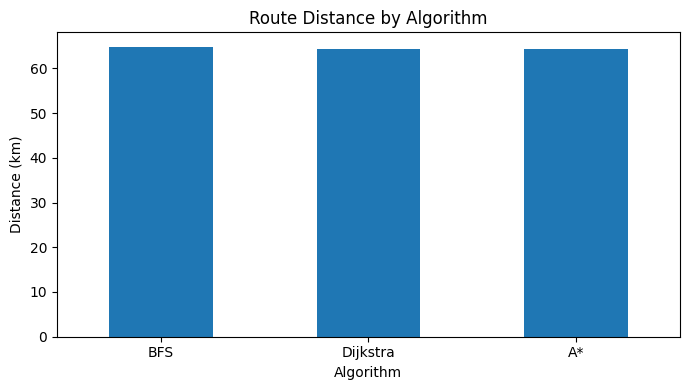

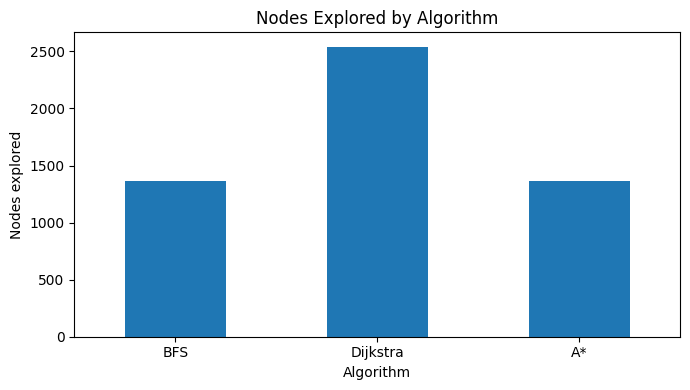

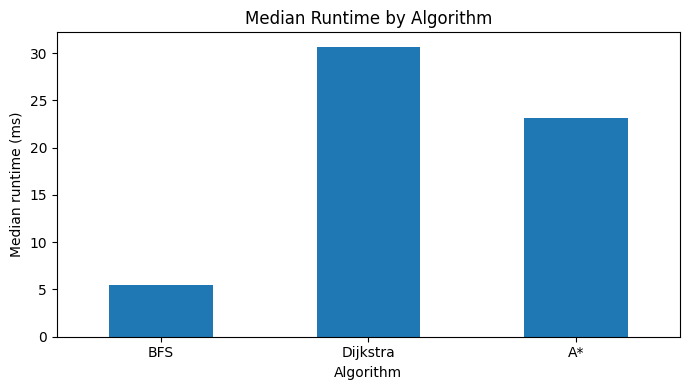

In [ ]:
plot_df = results_df.set_index("Algorithm")

for column, title, ylabel in [
    ("Route_Distance_km", "Route Distance by Algorithm", "Distance (km)"),
    ("Nodes_Explored", "Nodes Explored by Algorithm", "Nodes explored"),
    ("Median_Runtime_ms", "Median Runtime by Algorithm", "Median runtime (ms)")
]:
    ax = plot_df[column].plot(kind="bar", figsize=(7, 4), rot=0, title=title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Algorithm")
    plt.tight_layout()
    plt.show()

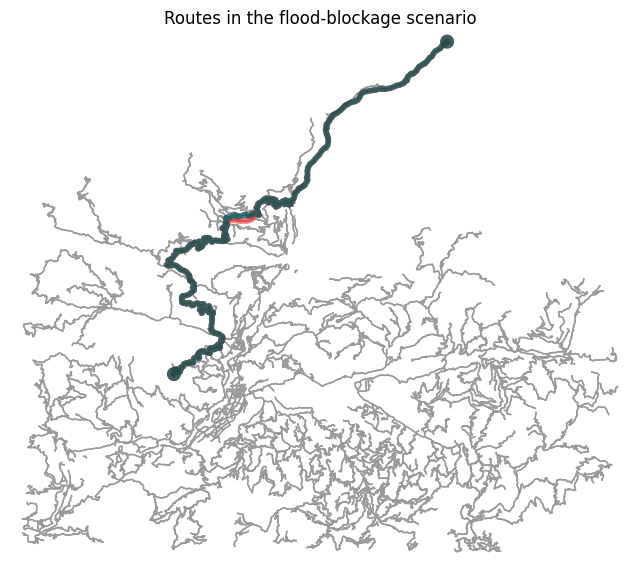

In [ ]:
# Plot routes on the projected graph. The list includes only routes found.
route_names = [name for name in ALGORITHMS if routes[name] is not None]
route_list = [routes[name] for name in route_names]

if route_list:
    colors = ["red", "blue", "green"][:len(route_list)]
    fig, ax = ox.plot_graph_routes(
        G_blocked,
        route_list,
        route_colors=colors,
        route_linewidth=3,
        node_size=0,
        bgcolor="white",
        show=False,
        close=False
    )
    ax.set_title("Routes in the flood-blockage scenario")
    plt.show()
else:
    print("No algorithm found a route between these endpoints.")

In [ ]:
# Stable hashes help document exactly which inputs/scenario were used.
def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

metadata = {
    "graph_file": GRAPH_FILE,
    "graph_sha256": file_sha256(GRAPH_FILE),
    "original_nodes": G_original.number_of_nodes(),
    "original_directed_edges": G_original.number_of_edges(),
    "scenario_nodes": G_blocked.number_of_nodes(),
    "scenario_directed_edges": G_blocked.number_of_edges(),
    "flood_record_count": len(flood_gdf),
    "match_threshold_m": MATCH_DISTANCE_M,
    "matched_records": int(matches_df["within_threshold"].sum()),
    "removed_directed_edges": len(edges_to_remove),
    "start_node": str(start_node),
    "goal_node": str(goal_node),
    "start_latlon": str(START_LATLON),
    "goal_latlon": str(GOAL_LATLON),
    "timing_repeats": TIMING_REPEATS,
    "random_seed": SEED,
    "osmnx_version": ox.__version__,
    "networkx_version": nx.__version__,
    "interpretation": "Simulated blockage scenario based on real flood-affected points; not all points are confirmed road closures."
}

metadata_df = pd.DataFrame([metadata])
results_path = os.path.join(PROJECT_DIR, "routing_results.csv")
matches_path = os.path.join(PROJECT_DIR, "flood_road_matches.csv")
metadata_path = os.path.join(PROJECT_DIR, "experiment_metadata.csv")

results_df.to_csv(results_path, index=False)
matches_df.to_csv(matches_path, index=False)
metadata_df.to_csv(metadata_path, index=False)

print("Saved files:")
print(results_path)
print(matches_path)
print(metadata_path)
display(metadata_df.T.rename(columns={0: "value"}))

Saved files:
/content/drive/MyDrive/nepal_flood_routing/routing_results.csv
/content/drive/MyDrive/nepal_flood_routing/flood_road_matches.csv
/content/drive/MyDrive/nepal_flood_routing/experiment_metadata.csv


,value
graph_file,/content/drive/MyDrive/nepal_flood_routing/nep...
graph_sha256,a133d9707f9f81a62ec7daea866f248d5838b059fcd43c...
original_nodes,2702
original_directed_edges,6176
scenario_nodes,2702
scenario_directed_edges,6150
flood_record_count,22
match_threshold_m,150
matched_records,16
removed_directed_edges,26


In [ ]:
# CELL R1: Validate that the existing notebook setup ran successfully.

required_names = [
    "G_projected", "flood_projected", "matches_df",
    "start_node", "goal_node", "PROJECT_DIR",
    "bfs_route", "dijkstra_route", "astar_route",
    "route_distance_m", "validate_path"
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the original notebook cells first. Missing: " + ", ".join(missing_names)
    )

import os, time, math, heapq, itertools, random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from shapely.geometry import LineString

SEED_RESEARCH = 42
random.seed(SEED_RESEARCH)
np.random.seed(SEED_RESEARCH)
os.makedirs(PROJECT_DIR, exist_ok=True)

print("Preflight check passed.")
print("Graph type:", type(G_projected).__name__)
print("Nodes:", G_projected.number_of_nodes())
print("Directed edges:", G_projected.number_of_edges())
print("Flood observations:", len(flood_projected))
print("Matched flood-road records:", len(matches_df))

Preflight check passed.
Graph type: MultiDiGraph
Nodes: 2702
Directed edges: 6176
Flood observations: 22
Matched flood-road records: 22


In [ ]:
# CELL R2: Assign a proximity-based risk proxy to each road edge.
# This score is NOT a measured flood depth or a validated probability of failure.

RISK_DISTANCE_SCALE_M = 500.0  # Modelling parameter; test alternatives in sensitivity analysis.
flood_geometries = [
    geom for geom in flood_projected.geometry
    if geom is not None and not geom.is_empty
]
if not flood_geometries:
    raise ValueError("No valid flood geometries are available.")

G_research = G_projected.copy()

def edge_geometry(graph, u, v, data):
    geom = data.get("geometry")
    if geom is not None and not geom.is_empty:
        return geom
    return LineString([
        (float(graph.nodes[u]["x"]), float(graph.nodes[u]["y"])),
        (float(graph.nodes[v]["x"]), float(graph.nodes[v]["y"]))
    ])

for u, v, key, data in G_research.edges(keys=True, data=True):
    geom = edge_geometry(G_research, u, v, data)
    nearest_distance = min(geom.distance(point) for point in flood_geometries)
    data["flood_distance_m"] = float(nearest_distance)
    data["risk_score"] = float(math.exp(-nearest_distance / RISK_DISTANCE_SCALE_M))

risk_scores = [d["risk_score"] for _, _, _, d in G_research.edges(keys=True, data=True)]
print("Risk scores assigned to", len(risk_scores), "directed edges.")
print("Risk score min/mean/max:", round(min(risk_scores), 4), round(float(np.mean(risk_scores)), 4), round(max(risk_scores), 4))

Risk scores assigned to 6176 directed edges.
Risk score min/mean/max: 0.0 0.0594 0.998


In [ ]:
# CELL R3: Create reproducible simulated blockage scenarios.
# A record within threshold metres of its matched road edge is treated as a
# simulated closure. Do not label it a verified closure without independent evidence.

BLOCKAGE_THRESHOLDS_M = [0, 50, 100, 150]

def build_research_scenario(threshold_m=None):
    graph = G_research.copy()
    if threshold_m is None or threshold_m == 0:
        return graph, 0

    required_cols = {"u", "v", "key", "distance_m"}
    if not required_cols.issubset(matches_df.columns):
        raise ValueError("matches_df must contain columns: " + str(required_cols))

    selected = matches_df[matches_df["distance_m"] <= threshold_m]
    to_remove = set()

    for _, row in selected.iterrows():
        u, v, key = row["u"], row["v"], row["key"]
        if graph.has_edge(u, v, key):
            to_remove.add((u, v, key))
            forward_data = graph.get_edge_data(u, v, key)
            forward_geom = edge_geometry(graph, u, v, forward_data)
            if graph.has_edge(v, u):
                for reverse_key, reverse_data in graph.get_edge_data(v, u).items():
                    reverse_geom = edge_geometry(graph, v, u, reverse_data)
                    if forward_geom.hausdorff_distance(reverse_geom) <= 5.0:
                        to_remove.add((v, u, reverse_key))

    graph.remove_edges_from(list(to_remove))
    return graph, len(to_remove)

scenario_rows = []
for threshold in BLOCKAGE_THRESHOLDS_M:
    graph, removed = build_research_scenario(threshold)
    scenario_rows.append({
        "Threshold_m": threshold,
        "Nodes": graph.number_of_nodes(),
        "Remaining_directed_edges": graph.number_of_edges(),
        "Removed_directed_edges": removed
    })
scenario_df = pd.DataFrame(scenario_rows)
display(scenario_df)
scenario_df.to_csv(os.path.join(PROJECT_DIR, "research_scenario_summary.csv"), index=False)

,Threshold_m,Nodes,Remaining_directed_edges,Removed_directed_edges
0,0,2702,6176,0
1,50,2702,6150,26
2,100,2702,6150,26
3,150,2702,6150,26


In [ ]:
# CELL R4: Risk-aware A* and route metrics.
# Objective: edge_length * (1 + lambda * risk_score).
# Since every risk score is >= 0, straight-line distance remains an admissible heuristic.

def choose_edge_attributes(graph, u, v, risk_weight=0.0):
    options = graph.get_edge_data(u, v)
    if not options:
        return None
    best_data = None
    best_cost = float("inf")
    for data in options.values():
        length = float(data.get("length", 1.0))
        risk = float(data.get("risk_score", 0.0))
        if length < 0:
            raise ValueError("Negative edge length encountered.")
        cost = length * (1.0 + risk_weight * risk)
        if cost < best_cost:
            best_cost, best_data = cost, data
    return best_data

def straight_line_heuristic(graph, node, target):
    dx = float(graph.nodes[node]["x"]) - float(graph.nodes[target]["x"])
    dy = float(graph.nodes[node]["y"]) - float(graph.nodes[target]["y"])
    return math.hypot(dx, dy)

def risk_aware_astar(graph, source, target, risk_weight=1.0):
    if source not in graph or target not in graph:
        return None, 0, float("inf")
    if source == target:
        return [source], 1, 0.0

    counter = itertools.count()
    best_g = {source: 0.0}
    parent = {source: None}
    closed = set()
    explored = 0
    queue = [(straight_line_heuristic(graph, source, target), 0.0, next(counter), source)]

    while queue:
        _, g_score, _, u = heapq.heappop(queue)
        if u in closed or g_score > best_g.get(u, float("inf")) + 1e-9:
            continue
        closed.add(u)
        explored += 1
        if u == target:
            path = []
            current = target
            while current is not None:
                path.append(current)
                current = parent[current]
            return path[::-1], explored, g_score

        for v in graph.successors(u):
            if v in closed:
                continue
            data = choose_edge_attributes(graph, u, v, risk_weight)
            if data is None:
                continue
            length = float(data.get("length", 1.0))
            risk = float(data.get("risk_score", 0.0))
            new_g = g_score + length * (1.0 + risk_weight * risk)
            if new_g + 1e-9 < best_g.get(v, float("inf")):
                best_g[v] = new_g
                parent[v] = u
                h = straight_line_heuristic(graph, v, target)
                heapq.heappush(queue, (new_g + h, new_g, next(counter), v))

    return None, explored, float("inf")

def route_metrics_with_risk(graph, path, risk_weight=0.0):
    if path is None:
        return {"distance_km": np.nan, "risk_exposure_km_equiv": np.nan,
                "mean_risk_weighted_by_length": np.nan, "route_edges": np.nan}
    distance_m = 0.0
    exposure_m = 0.0
    for u, v in zip(path[:-1], path[1:]):
        data = choose_edge_attributes(graph, u, v, risk_weight)
        if data is None:
            raise ValueError(f"Path contains missing edge {u}->{v}.")
        length = float(data.get("length", 1.0))
        risk = float(data.get("risk_score", 0.0))
        distance_m += length
        exposure_m += length * risk
    mean_risk = exposure_m / distance_m if distance_m > 0 else 0.0
    return {
        "distance_km": distance_m / 1000.0,
        "risk_exposure_km_equiv": exposure_m / 1000.0,
        "mean_risk_weighted_by_length": mean_risk,
        "route_edges": len(path) - 1
    }

print("Risk-aware A* and route metrics are ready.")

Risk-aware A* and route metrics are ready.


In [ ]:
# CELL R5: Build a fixed set of origin-destination pairs.
# The selected pair is included when possible; additional pairs are sampled
# reproducibly from the largest weakly connected component.

undirected = G_research.to_undirected()
components = list(nx.connected_components(undirected))
if not components:
    raise ValueError("Road graph has no connected components.")
largest_component = max(components, key=len)
candidates = list(largest_component)
rng = random.Random(SEED_RESEARCH)
od_pairs = []

if start_node in largest_component and goal_node in largest_component and start_node != goal_node:
    od_pairs.append(("Selected_OD", start_node, goal_node))

TARGET_OD_PAIRS = 5
attempts = 0
while len(od_pairs) < TARGET_OD_PAIRS and attempts < 5000:
    attempts += 1
    source, target = rng.sample(candidates, 2)
    if source == target:
        continue
    if any(source == s and target == t for _, s, t in od_pairs):
        continue
    od_pairs.append((f"OD_{len(od_pairs)+1}", source, target))

if not od_pairs:
    raise ValueError("Could not construct any valid origin-destination pairs.")

print("OD pairs:", len(od_pairs))
for name, source, target in od_pairs:
    print(name, "| source:", source, "| target:", target)

OD pairs: 5
Selected_OD | source: 3477704236 | target: 14130888037
OD_2 | source: 3476569847 | target: 14131242359
OD_3 | source: 3071451459 | target: 14126968199
OD_4 | source: 10828983272 | target: 10685065970
OD_5 | source: 268330771 | target: 8259134744


In [ ]:
# CELL R6: Run baseline and risk-aware algorithms.
# Runtime is measured over repeated executions. Keep the same graph and endpoints
# for all algorithms within each scenario.

TIMING_REPEATS_RESEARCH = 5
RISK_WEIGHTS = [0.0, 0.5, 1.0, 2.0]
SCENARIOS_RESEARCH = [("No_closures", None)] + [
    (f"Threshold_{t}m", t) for t in [50, 100, 150]
]

baseline_functions = {
    "BFS": bfs_route,
    "Dijkstra": dijkstra_route,
    "A_star_distance": astar_route
}

baseline_rows = []
risk_rows = []

for scenario_name, threshold in SCENARIOS_RESEARCH:
    if threshold is None:
        scenario_graph = G_research.copy()
        removed_edges = 0
    else:
        scenario_graph, removed_edges = build_research_scenario(threshold)

    for od_name, source, target in od_pairs:
        # Baseline algorithms
        for algorithm_name, algorithm in baseline_functions.items():
            timings = []
            path, explored = None, 0
            for _ in range(TIMING_REPEATS_RESEARCH):
                t0 = time.perf_counter()
                path, explored = algorithm(scenario_graph, source, target)
                timings.append((time.perf_counter() - t0) * 1000.0)
            valid = validate_path(scenario_graph, path, source, target)
            distance_m = route_distance_m(scenario_graph, path) if valid else np.nan
            baseline_rows.append({
                "Scenario": scenario_name, "Threshold_m": threshold,
                "OD_pair": od_name, "Algorithm": algorithm_name,
                "Route_found": path is not None, "Path_valid": valid,
                "Distance_km": distance_m / 1000.0 if valid else np.nan,
                "Nodes_explored": explored,
                "Median_runtime_ms": float(np.median(timings)),
                "Runtime_std_ms": float(np.std(timings, ddof=1)) if len(timings) > 1 else 0.0,
                "Removed_directed_edges": removed_edges
            })

        # Risk-aware A* across risk penalties
        for risk_weight in RISK_WEIGHTS:
            timings = []
            path, explored, objective_cost = None, 0, float("inf")
            for _ in range(TIMING_REPEATS_RESEARCH):
                t0 = time.perf_counter()
                path, explored, objective_cost = risk_aware_astar(
                    scenario_graph, source, target, risk_weight=risk_weight
                )
                timings.append((time.perf_counter() - t0) * 1000.0)
            metrics = route_metrics_with_risk(scenario_graph, path, risk_weight)
            risk_rows.append({
                "Scenario": scenario_name, "Threshold_m": threshold,
                "OD_pair": od_name, "Risk_weight_lambda": risk_weight,
                "Route_found": path is not None,
                "Objective_cost_m_equivalent": objective_cost if path is not None else np.nan,
                **metrics,
                "Nodes_explored": explored,
                "Median_runtime_ms": float(np.median(timings)),
                "Runtime_std_ms": float(np.std(timings, ddof=1)) if len(timings) > 1 else 0.0,
                "Removed_directed_edges": removed_edges
            })

baseline_results_df = pd.DataFrame(baseline_rows)
risk_results_df = pd.DataFrame(risk_rows)

print("BASELINE RESULTS")
display(baseline_results_df.head(20))
print("RISK-AWARE RESULTS")
display(risk_results_df.head(20))

baseline_results_df.to_csv(os.path.join(PROJECT_DIR, "baseline_algorithm_comparison.csv"), index=False)
risk_results_df.to_csv(os.path.join(PROJECT_DIR, "risk_aware_experiments.csv"), index=False)
print("Saved both experiment datasets to:", PROJECT_DIR)

BASELINE RESULTS


,Scenario,Threshold_m,OD_pair,Algorithm,Route_found,Path_valid,Distance_km,Nodes_explored,Median_runtime_ms,Runtime_std_ms,Removed_directed_edges
0,No_closures,NaN,Selected_OD,BFS,True,True,64.810792,1619,2.228303,0.290167,0
1,No_closures,NaN,Selected_OD,Dijkstra,True,True,64.353923,2702,12.379059,0.931762,0
2,No_closures,NaN,Selected_OD,A_star_distance,True,True,64.353923,1562,9.769433,0.368526,0
3,No_closures,NaN,OD_2,BFS,True,True,30.971337,1407,2.295263,0.390848,0
4,No_closures,NaN,OD_2,Dijkstra,True,True,16.390073,455,1.850029,0.186680,0
5,No_closures,NaN,OD_2,A_star_distance,True,True,16.390073,306,1.814361,0.135723,0
6,No_closures,NaN,OD_3,BFS,True,True,45.859197,2512,4.007105,0.147124,0
7,No_closures,NaN,OD_3,Dijkstra,True,True,45.851631,2637,14.371149,1.072698,0
8,No_closures,NaN,OD_3,A_star_distance,True,True,45.851631,1800,11.045487,0.820614,0
9,No_closures,NaN,OD_4,BFS,True,True,12.550023,240,0.297687,0.051246,0


RISK-AWARE RESULTS


,Scenario,Threshold_m,OD_pair,Risk_weight_lambda,Route_found,Objective_cost_m_equivalent,distance_km,risk_exposure_km_equiv,mean_risk_weighted_by_length,route_edges,Nodes_explored,Median_runtime_ms,Runtime_std_ms,Removed_directed_edges
0,No_closures,NaN,Selected_OD,0.0,True,64353.922793,64.353923,0.240115,0.003731,54,1562,9.601211,0.142063,0
1,No_closures,NaN,Selected_OD,0.5,True,64473.980151,64.353923,0.240115,0.003731,54,1526,10.329437,0.628806,0
2,No_closures,NaN,Selected_OD,1.0,True,64594.037509,64.353923,0.240115,0.003731,54,1470,10.218756,0.823466,0
3,No_closures,NaN,Selected_OD,2.0,True,64834.152224,64.353923,0.240115,0.003731,54,1396,11.033626,0.855357,0
4,No_closures,NaN,OD_2,0.0,True,16390.072974,16.390073,4.035174,0.246196,60,306,1.900554,0.209804,0
5,No_closures,NaN,OD_2,0.5,True,18407.660091,16.390073,4.035174,0.246196,60,308,1.925509,0.544862,0
6,No_closures,NaN,OD_2,1.0,True,20425.247209,16.390073,4.035174,0.246196,60,312,2.057617,0.212231,0
7,No_closures,NaN,OD_2,2.0,True,24199.503928,16.755168,3.722168,0.222150,63,331,1.836558,0.136997,0
8,No_closures,NaN,OD_3,0.0,True,45851.630813,45.851631,2.295194,0.050057,55,1800,11.796384,0.550820,0
9,No_closures,NaN,OD_3,0.5,True,46999.227858,45.851631,2.295194,0.050057,55,1727,11.797051,0.708749,0


Saved both experiment datasets to: /content/drive/MyDrive/nepal_flood_routing


In [ ]:
# CELL R7: Create paper-ready summary tables.

baseline_summary_df = (
    baseline_results_df.groupby(["Scenario", "Algorithm"], dropna=False)
    .agg(
        OD_pairs_tested=("OD_pair", "nunique"),
        Successful_routes=("Route_found", "sum"),
        Mean_distance_km=("Distance_km", "mean"),
        Mean_nodes_explored=("Nodes_explored", "mean"),
        Median_runtime_ms=("Median_runtime_ms", "median")
    ).reset_index()
)
baseline_summary_df["Success_rate_pct"] = (
    baseline_summary_df["Successful_routes"] /
    baseline_summary_df["OD_pairs_tested"] * 100.0
)

risk_summary_df = (
    risk_results_df.groupby(["Scenario", "Risk_weight_lambda"], dropna=False)
    .agg(
        OD_pairs_tested=("OD_pair", "nunique"),
        Successful_routes=("Route_found", "sum"),
        Mean_distance_km=("distance_km", "mean"),
        Mean_risk_exposure_km_equiv=("risk_exposure_km_equiv", "mean"),
        Mean_route_risk=("mean_risk_weighted_by_length", "mean"),
        Mean_nodes_explored=("Nodes_explored", "mean"),
        Median_runtime_ms=("Median_runtime_ms", "median")
    ).reset_index()
)
risk_summary_df["Success_rate_pct"] = (
    risk_summary_df["Successful_routes"] /
    risk_summary_df["OD_pairs_tested"] * 100.0
)

display(baseline_summary_df.round(4))
display(risk_summary_df.round(4))

baseline_summary_df.to_csv(os.path.join(PROJECT_DIR, "baseline_algorithm_summary.csv"), index=False)
risk_summary_df.to_csv(os.path.join(PROJECT_DIR, "risk_aware_summary.csv"), index=False)

,Scenario,Algorithm,OD_pairs_tested,Successful_routes,Mean_distance_km,Mean_nodes_explored,Median_runtime_ms,Success_rate_pct
0,No_closures,A_star_distance,5,5,34.0214,901.6,9.7694,100.0
1,No_closures,BFS,5,5,42.1657,1398.6,2.2953,100.0
2,No_closures,Dijkstra,5,5,34.0214,1664.0,12.3791,100.0
3,Threshold_100m,A_star_distance,5,5,38.9952,960.8,16.0563,100.0
4,Threshold_100m,BFS,5,5,47.7037,1329.2,10.6324,100.0
5,Threshold_100m,Dijkstra,5,5,38.9952,1600.8,28.9919,100.0
6,Threshold_150m,A_star_distance,5,5,38.9952,960.8,10.3528,100.0
7,Threshold_150m,BFS,5,5,47.7037,1329.2,1.7715,100.0
8,Threshold_150m,Dijkstra,5,5,38.9952,1600.8,12.4748,100.0
9,Threshold_50m,A_star_distance,5,5,38.9952,960.8,14.9544,100.0


,Scenario,Risk_weight_lambda,OD_pairs_tested,Successful_routes,Mean_distance_km,Mean_risk_exposure_km_equiv,Mean_route_risk,Mean_nodes_explored,Median_runtime_ms,Success_rate_pct
0,No_closures,0.0,5,5,34.0214,2.7390,0.0993,901.6,9.6012,100.0
1,No_closures,0.5,5,5,34.0214,2.7390,0.0993,918.8,10.0870,100.0
2,No_closures,1.0,5,5,34.0214,2.7390,0.0993,924.2,10.2188,100.0
3,No_closures,2.0,5,5,35.2734,1.7140,0.0662,906.6,10.2822,100.0
4,Threshold_100m,0.0,5,5,38.9952,3.3473,0.0912,960.8,14.8270,100.0
5,Threshold_100m,0.5,5,5,39.2977,2.6307,0.0801,965.8,20.4377,100.0
6,Threshold_100m,1.0,5,5,39.2977,2.6307,0.0801,969.8,20.1271,100.0
7,Threshold_100m,2.0,5,5,39.6573,2.3224,0.0719,974.2,22.2036,100.0
8,Threshold_150m,0.0,5,5,38.9952,3.3473,0.0912,960.8,7.9443,100.0
9,Threshold_150m,0.5,5,5,39.2977,2.6307,0.0801,965.8,6.1447,100.0


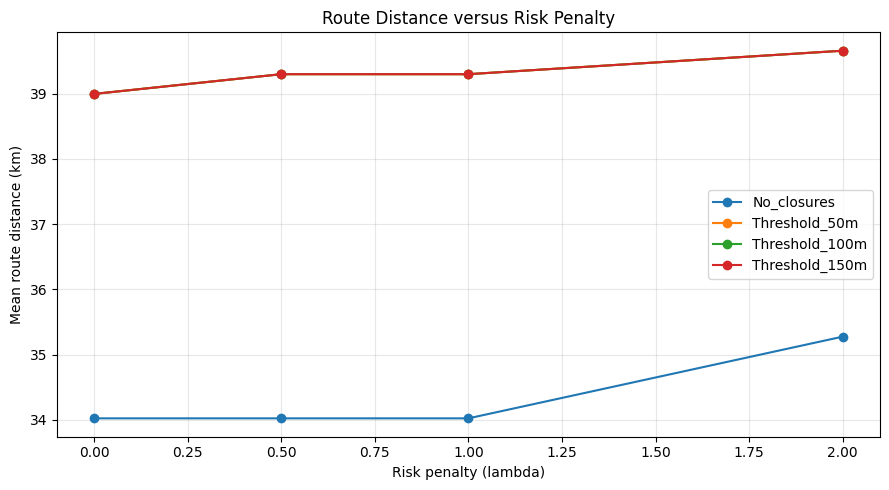

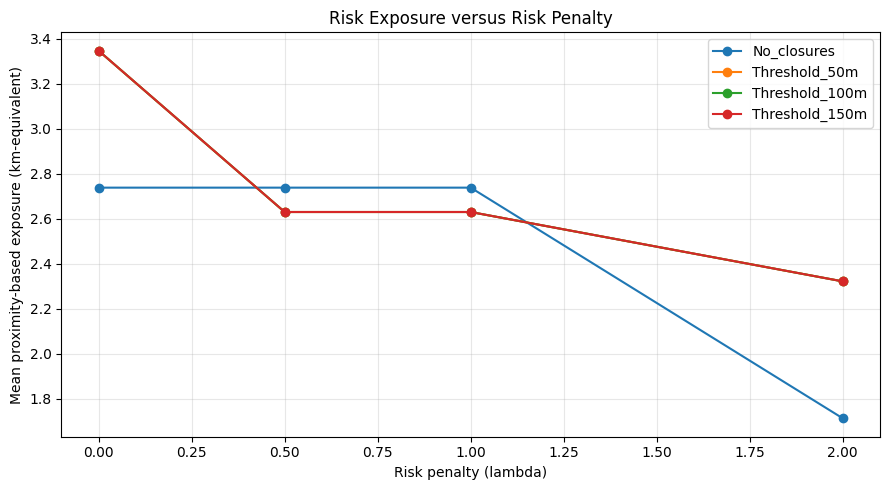

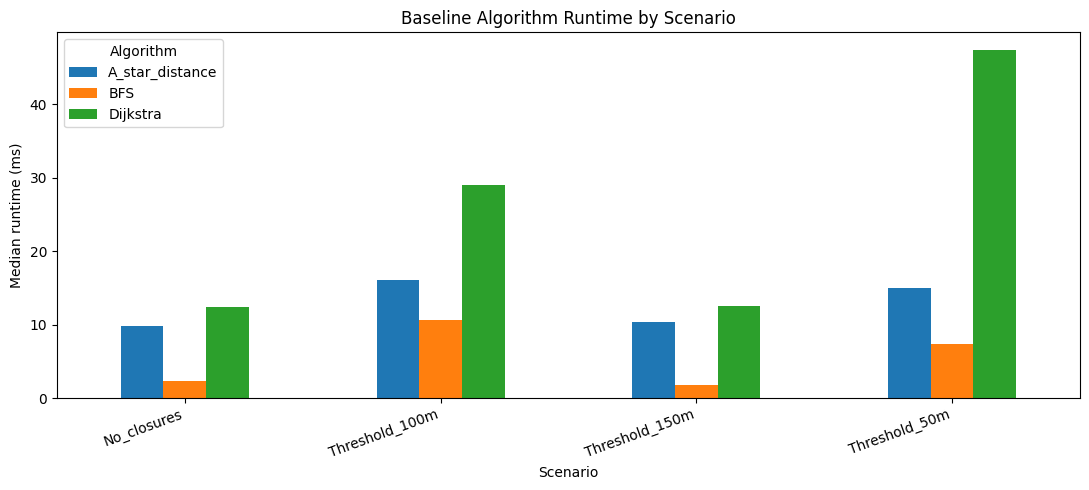

In [ ]:
# CELL R8: Plot the main findings.

# Plot 1: mean physical distance versus risk penalty.
plot_data = risk_results_df[risk_results_df["Route_found"] == True]
plt.figure(figsize=(9, 5))
for scenario in plot_data["Scenario"].dropna().unique():
    subset = plot_data[plot_data["Scenario"] == scenario]
    means = subset.groupby("Risk_weight_lambda")["distance_km"].mean().sort_index()
    plt.plot(means.index, means.values, marker="o", label=scenario)
plt.xlabel("Risk penalty (lambda)")
plt.ylabel("Mean route distance (km)")
plt.title("Route Distance versus Risk Penalty")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: mean risk exposure versus risk penalty.
plt.figure(figsize=(9, 5))
for scenario in plot_data["Scenario"].dropna().unique():
    subset = plot_data[plot_data["Scenario"] == scenario]
    means = subset.groupby("Risk_weight_lambda")["risk_exposure_km_equiv"].mean().sort_index()
    plt.plot(means.index, means.values, marker="o", label=scenario)
plt.xlabel("Risk penalty (lambda)")
plt.ylabel("Mean proximity-based exposure (km-equivalent)")
plt.title("Risk Exposure versus Risk Penalty")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 3: median runtime of baseline algorithms by scenario.
runtime_data = baseline_results_df.groupby(["Scenario", "Algorithm"])["Median_runtime_ms"].median().unstack()
ax = runtime_data.plot(kind="bar", figsize=(11, 5))
ax.set_xlabel("Scenario")
ax.set_ylabel("Median runtime (ms)")
ax.set_title("Baseline Algorithm Runtime by Scenario")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# CELL R9: Correctness checks and final export.
# Distance-only A* should agree with Dijkstra on the same graph.
check_graph = G_research.copy()
d_path, d_explored = dijkstra_route(check_graph, start_node, goal_node)
a_path, a_explored = astar_route(check_graph, start_node, goal_node)
d_distance = route_distance_m(check_graph, d_path) if d_path is not None else None
a_distance = route_distance_m(check_graph, a_path) if a_path is not None else None

if d_distance is None and a_distance is None:
    print("Neither Dijkstra nor A* found a route for the selected pair.")
elif d_distance is None or a_distance is None:
    raise AssertionError("Dijkstra and A* disagree about route availability.")
else:
    print("Dijkstra distance (km):", round(d_distance / 1000.0, 4))
    print("A* distance (km):", round(a_distance / 1000.0, 4))
    assert np.isclose(d_distance, a_distance, rtol=1e-7, atol=0.1), \
        "Dijkstra and A* distances differ. Check edge weights and heuristic."
    print("PASS: Dijkstra and A* return the same optimal distance.")

print("\nFiles written to:", PROJECT_DIR)
for filename in [
    "research_scenario_summary.csv",
    "baseline_algorithm_comparison.csv",
    "baseline_algorithm_summary.csv",
    "risk_aware_experiments.csv",
    "risk_aware_summary.csv"
]:
    filepath = os.path.join(PROJECT_DIR, filename)
    print(filename, "->", "exists" if os.path.exists(filepath) else "not yet created")

print("\nResearch caution: flood proximity is a proxy, and threshold-based closures are simulated unless independently verified.")

Dijkstra distance (km): 64.3539
A* distance (km): 64.3539
PASS: Dijkstra and A* return the same optimal distance.

Files written to: /content/drive/MyDrive/nepal_flood_routing
research_scenario_summary.csv -> exists
baseline_algorithm_comparison.csv -> exists
baseline_algorithm_summary.csv -> exists
risk_aware_experiments.csv -> exists
risk_aware_summary.csv -> exists

Research caution: flood proximity is a proxy, and threshold-based closures are simulated unless independently verified.
